# Scoring de crédit explicable : analyse

Jeu **Default of Credit Card Clients** (Taiwan, 2005), UCI, identifiant 350,
licence CC BY 4.0. Cible `DEFAULT` : défaut de paiement le mois suivant (1 = défaut).

Ce notebook utilise le même code que l'application (`src/credit_scoring`).

## 1. Données : vérifications avant utilisation

Objectif : vérifier sur les vraies données ce qui est annoncé (dimensions, absence de valeurs
manquantes, taux de défaut) et examiner les modalités non documentées avant de décider
d'un recodage. Les décisions sont détaillées dans `docs/CHOIX.md` (C04, R1 à R5).

In [1]:
from math import comb, sqrt

import pandas as pd

from credit_scoring.config import (
    BILL_FEATURES, PAY_AMT_FEATURES, PAY_STATUS_FEATURES, TARGET,
)
from credit_scoring.data import load_credit_data, recode_undocumented

pd.set_option("display.max_columns", 30)
raw = load_credit_data()  # téléchargement au premier appel, puis cache local
raw.head()

,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6,BILL_AMT1,BILL_AMT2,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,DEFAULT
ID,,,,,,,,,,,,,,,,,,,,,,,,
1,20000,2,2,1,24,2,2,-1,-1,-2,-2,3913,3102,689,0,0,0,0,689,0,0,0,0,1
2,120000,2,2,2,26,-1,2,0,0,0,2,2682,1725,2682,3272,3455,3261,0,1000,1000,1000,0,2000,1
3,90000,2,2,2,34,0,0,0,0,0,0,29239,14027,13559,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
4,50000,2,2,1,37,0,0,0,0,0,0,46990,48233,49291,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
5,50000,1,2,1,57,-1,0,-1,0,0,0,8617,5670,35835,20940,19146,19131,2000,36681,10000,9000,689,679,0


### 1.1 Dimensions, types, valeurs manquantes

In [2]:
print("Dimensions :", raw.shape)
print("Types :", raw.dtypes.astype(str).value_counts().to_dict())
print("Valeurs manquantes :", int(raw.isna().sum().sum()))

Dimensions : (30000, 24)
Types : {'int64': 24}
Valeurs manquantes : 0


Toutes les colonnes sont des entiers, y compris `SEX`, `EDUCATION` et `MARRIAGE`, qui sont
pourtant des catégories sans ordre : elles seront déclarées explicitement comme catégorielles (P01).

### 1.2 Taux de défaut

In [3]:
counts = raw[TARGET].value_counts().rename("clients").to_frame()
counts["part (%)"] = (counts["clients"] / len(raw) * 100).round(2)
counts

,clients,part (%)
DEFAULT,,
0,23364,77.88
1,6636,22.12


Environ 22 % de défauts : un modèle qui prédirait toujours « pas de défaut » aurait 78 % de
bonnes réponses tout en étant inutile. Les modèles seront donc comparés sur l'AUC, le rappel et la
PR-AUC plutôt que sur le taux de bonnes réponses.

### 1.3 Variables catégorielles et modalités non documentées

Codes officiels (UCI) : SEX 1 = homme, 2 = femme ; EDUCATION 1 = 3e cycle, 2 = université,
3 = lycée, 4 = autres ; MARRIAGE 1 = marié, 2 = célibataire, 3 = autres.

In [4]:
def taux_par_modalite(df, col):
    """Effectif et taux de défaut (%) par modalité d'une variable."""
    t = df.groupby(col)[TARGET].agg(clients="size", defauts="sum", taux_defaut="mean")
    t["taux_defaut"] = (t["taux_defaut"] * 100).round(1)
    return t.T


taux_par_modalite(raw, "SEX")

SEX,1,2
clients,11888.0,18112.0
defauts,2873.0,3763.0
taux_defaut,24.2,20.8


In [5]:
taux_par_modalite(raw, "EDUCATION")

EDUCATION,0,1,2,3,4,5,6
clients,14.0,10585.0,14030.0,4917.0,123.0,280.0,51.0
defauts,0.0,2036.0,3330.0,1237.0,7.0,18.0,8.0
taux_defaut,0.0,19.2,23.7,25.2,5.7,6.4,15.7


Les codes 0, 5 et 6 ne sont pas documentés par l'UCI (la description Kaggle du même jeu indique
5 = unknown et 6 = unknown ; le code 0 n'est documenté nulle part). Ils concernent 345 clients (1,2 %),
avec un taux de défaut bas, proche de celui du code 4 « autres ». **R1 :** regroupement dans 4,
libellé « Autres ou inconnu ».

In [6]:
taux_par_modalite(raw, "MARRIAGE")

MARRIAGE,0,1,2,3
clients,54.0,13659.0,15964.0,323.0
defauts,5.0,3206.0,3341.0,84.0
taux_defaut,9.3,23.5,20.9,26.0


Le code 0 n'est pas documenté. Son taux de défaut (9,3 %) semble très différent de celui de
« autres » (26,0 %) : on le vérifie par un test exact de Fisher (adapté aux petits effectifs).

In [7]:
def fisher_bilateral(d0, n0, d1, n1):
    """Test exact de Fisher bilatéral sur un tableau 2x2 (défauts / clients de deux groupes)."""
    k_tot, n_tot = d0 + d1, n0 + n1

    def proba(k):
        return comb(k_tot, k) * comb(n_tot - k_tot, n0 - k) / comb(n_tot, n0)

    p_obs = proba(d0)
    support = range(max(0, n0 - (n_tot - k_tot)), min(k_tot, n0) + 1)
    return sum(proba(k) for k in support if proba(k) <= p_obs * (1 + 1e-9))


def wilson(d, n, z=1.959964):
    """Intervalle de confiance à 95 % d'une proportion (méthode de Wilson)."""
    p = d / n
    centre = (p + z * z / (2 * n)) / (1 + z * z / n)
    demi = z * sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / (1 + z * z / n)
    return round(100 * (centre - demi), 1), round(100 * (centre + demi), 1)


groupes = raw.groupby("MARRIAGE")[TARGET].agg(defauts="sum", clients="size")
d0, n0 = groupes.loc[0]
d3, n3 = groupes.loc[3]
print(f"Code 0 : {d0}/{n0} = {d0 / n0:.1%}, IC 95 % {wilson(d0, n0)}")
print(f"Code 3 : {d3}/{n3} = {d3 / n3:.1%}, IC 95 % {wilson(d3, n3)}")
print(f"Test exact de Fisher bilatéral : p = {fisher_bilateral(d0, n0, d3, n3):.4f}")

Code 0 : 5/54 = 9.3%, IC 95 % (4.0, 19.9)
Code 3 : 84/323 = 26.0%, IC 95 % (21.5, 31.1)
Test exact de Fisher bilatéral : p = 0.0055


L'écart est **statistiquement significatif** (p < 0,05) et les intervalles de confiance ne se
chevauchent pas. **R2 :** le code 0 est tout de même regroupé avec 3, parce qu'il n'a pas de sens
documenté et que 54 clients sur 30 000 ne peuvent pas peser sur le modèle. Conséquence : le taux de
« autres » passe de 26,0 % à 23,6 %.

### 1.4 Statuts de remboursement PAY_*

Documentation UCI : -1 = payé à temps, 1…9 = mois de retard. Les codes -2 et 0 ne sont pas documentés.
PAY_0 = septembre, PAY_2 = août, …, PAY_6 = avril.

In [8]:
modalites_pay = pd.DataFrame({c: raw[c].value_counts() for c in PAY_STATUS_FEATURES})
modalites_pay.fillna(0).astype(int).sort_index().T

,-2,-1,0,1,2,3,4,5,6,7,8
PAY_0,2759,5686,14737,3688,2667,322,76,26,11,9,19
PAY_2,3782,6050,15730,28,3927,326,99,25,12,20,1
PAY_3,4085,5938,15764,4,3819,240,76,21,23,27,3
PAY_4,4348,5687,16455,2,3159,180,69,35,5,58,2
PAY_5,4546,5539,16947,0,2626,178,84,17,4,58,1
PAY_6,4895,5740,16286,0,2766,184,49,13,19,46,2


In [9]:
taux_par_modalite(raw, "PAY_0")

PAY_0,-2,-1,0,1,2,3,4,5,6,7,8
clients,2759.0,5686.0,14737.0,3688.0,2667.0,322.0,76.0,26.0,11.0,9.0,19.0
defauts,365.0,954.0,1888.0,1252.0,1844.0,244.0,52.0,13.0,6.0,7.0,11.0
taux_defaut,13.2,16.8,12.8,33.9,69.1,75.8,68.4,50.0,54.5,77.8,57.9


In [10]:
factures_nulles = raw["BILL_AMT1"] <= 0
for code_pay in (-2, -1, 0):
    part = factures_nulles[raw["PAY_0"] == code_pay].mean()
    print(f"PAY_0 = {code_pay:>2} : {part:.1%} des clients ont une facture de septembre nulle ou négative")

PAY_0 = -2 : 32.7% des clients ont une facture de septembre nulle ou négative
PAY_0 = -1 : 0.1% des clients ont une facture de septembre nulle ou négative
PAY_0 =  0 : 0.0% des clients ont une facture de septembre nulle ou négative


- -2 et 0 sont très fréquents : ce ne sont pas des erreurs isolées. Interprétation la plus répandue :
  -2 = pas d'utilisation, -1 = payé en totalité, 0 = crédit renouvelable (minimum payé). Les données
  vont dans ce sens : aucun client à 0 n'a de facture nulle, contre un tiers des clients à -2.
- Le risque est plat de -2 à 0 (13 à 17 %), puis saute à 1 mois de retard (34 %) et à 2 mois (69 %) :
  l'ordre a du sens, mais la relation n'est pas linéaire (M05, à vérifier à l'étape de modélisation).
- **Anomalie :** la valeur 1 concerne 3 688 clients en septembre, mais presque aucun les autres mois.
  Le codage a probablement changé d'un mois à l'autre ; limite à citer.
- **R3 :** aucun recodage des PAY_*.

### 1.5 Clients aux variables identiques

In [11]:
variables = [c for c in raw.columns if c != TARGET]
groupes_id = raw.groupby(variables)[TARGET].agg(["size", "nunique"])
groupes_id = groupes_id[groupes_id["size"] > 1]
print("Groupes de clients aux 23 variables identiques :", len(groupes_id),
      "| lignes :", int(groupes_id["size"].sum()))
print("dont groupes avec des cibles différentes :", int((groupes_id["nunique"] > 1).sum()))

Groupes de clients aux 23 variables identiques : 52 | lignes : 108
dont groupes avec des cibles différentes : 21


Ce sont surtout des comptes inactifs (factures et paiements à 0) avec des identifiants distincts :
des clients différents au profil identique. **R4 :** conservés (0,36 % des lignes).

In [12]:
inactifs = raw[BILL_FEATURES + PAY_AMT_FEATURES].eq(0).all(axis=1)
print(f"Comptes inactifs (factures et paiements à 0) : {inactifs.sum()} clients, "
      f"taux de défaut {raw.loc[inactifs, TARGET].mean():.1%} (moyenne : {raw[TARGET].mean():.1%})")

Comptes inactifs (factures et paiements à 0) : 795 clients, taux de défaut 37.6% (moyenne : 22.1%)


Faire défaut sans jamais rien dépenser est contre-intuitif : soit la définition du défaut dans ce
jeu est plus large qu'un impayé, soit les étiquettes contiennent du bruit. Observation à reprendre dans
l'analyse critique.

### 1.6 Montants, âge et plafond

In [13]:
montants = pd.DataFrame({
    "factures négatives": (raw[BILL_FEATURES] < 0).sum(),
    "minimum": raw[BILL_FEATURES].min(),
    "maximum": raw[BILL_FEATURES].max(),
})
print("Paiements négatifs :", int((raw[PAY_AMT_FEATURES] < 0).sum().sum()))
print("Clients avec une facture de septembre supérieure au plafond :",
      int((raw["BILL_AMT1"] > raw["LIMIT_BAL"]).sum()))
montants.T

Paiements négatifs : 0
Clients avec une facture de septembre supérieure au plafond : 2115


,BILL_AMT1,BILL_AMT2,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6
factures négatives,590,669,655,675,655,688
minimum,-165580,-69777,-157264,-170000,-81334,-339603
maximum,964511,983931,1664089,891586,927171,961664


In [14]:
raw[["AGE", "LIMIT_BAL"]].describe().T

,count,mean,std,min,25%,50%,75%,max
AGE,30000.0,35.485500,9.217904,21.0,28.0,34.0,41.0,79.0
LIMIT_BAL,30000.0,167484.322667,129747.661567,10000.0,50000.0,140000.0,240000.0,1000000.0


Les factures négatives sont des soldes créditeurs (trop-perçu) ; les dépassements de plafond
s'expliquent par les intérêts et les frais. Âges (21 à 79 ans) et plafonds plausibles.
**R5 :** valeurs conservées.

### 1.7 Recodage retenu

Règle fixe appliquée ligne par ligne (elle n'apprend rien des données) : EDUCATION 0, 5, 6 → 4 ;
MARRIAGE 0 → 3 ; PAY_* inchangées.

In [15]:
df = recode_undocumented(raw)
print("PAY_* inchangées :", raw[PAY_STATUS_FEATURES].equals(df[PAY_STATUS_FEATURES]))
taux_par_modalite(df, "EDUCATION")

PAY_* inchangées : True


EDUCATION,1,2,3,4
clients,10585.0,14030.0,4917.0,468.0
defauts,2036.0,3330.0,1237.0,33.0
taux_defaut,19.2,23.7,25.2,7.1


In [16]:
taux_par_modalite(df, "MARRIAGE")

MARRIAGE,1,2,3
clients,13659.0,15964.0,377.0
defauts,3206.0,3341.0,89.0
taux_defaut,23.5,20.9,23.6


### Synthèse de la section 1

| Vérification | Résultat |
|---|---|
| Dimensions | 30 000 clients, 23 variables + cible, toutes entières |
| Valeurs manquantes | 0 |
| Taux de défaut | 22,12 % |
| EDUCATION 0, 5, 6 | 345 clients, regroupés dans « Autres ou inconnu » (R1) |
| MARRIAGE 0 | 54 clients, écart significatif (Fisher p ≈ 0,006), regroupés dans « Autres » (R2) |
| PAY_* | -2 et 0 fréquents, relation non linéaire avec le risque, pas de recodage (R3) |
| Profils identiques | 52 groupes, conservés (R4) |
| Montants | soldes créditeurs et dépassements réalistes, conservés (R5) |

## 2. Exploration visuelle

Graphiques Matplotlib (images fixes, lisibles sur GitHub) ; l'application propose les mêmes
graphiques en version interactive (Plotly). Toutes les analyses portent sur les données recodées
(`df`, section 1.7). Couleurs : bleu = pas de défaut, orange = défaut (choix C11).

In [17]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Patch

from credit_scoring.config import CATEGORICAL_FEATURES
from credit_scoring.eda import positive_rate_by
from credit_scoring.plots import CLASS_COLORS, DIVERGING, MUTED, RATE_COLOR

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#c3c2b7",
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": "#e1e0d9",
    "grid.linewidth": 0.6,
    "axes.titlesize": 11,
    "axes.titleweight": "bold",
    "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e",
    "ytick.color": "#52514e",
})
NOMS_CLASSES = {0: "Pas de défaut", 1: "Défaut"}
TAUX_MOYEN = df[TARGET].mean() * 100
PETIT_EFFECTIF = 30  # en dessous, la barre est grisée : taux instable
GRIS = "#c3c2b7"


def barres_taux(ax, table, titre, etiquettes=None, valeurs=True):
    """Barres du taux de défaut par groupe, avec la moyenne en pointillés."""
    x = etiquettes if etiquettes is not None else table.index.astype(str)
    couleurs = [RATE_COLOR if n >= PETIT_EFFECTIF else GRIS for n in table["clients"]]
    barres = ax.bar(x, table["taux (%)"], color=couleurs, width=0.7)
    ax.axhline(TAUX_MOYEN, color=MUTED, linestyle="--", linewidth=1)
    if valeurs:
        # Valeurs à l'intérieur du haut des barres : pas de collision avec la ligne de moyenne.
        ax.bar_label(barres, fmt="%.1f", fontsize=8, color="white", padding=-12)
    ax.set_title(titre)
    ax.grid(axis="x", visible=False)
    return ax


def note_moyenne(fig):
    """Légende commune en haut de la figure (évite de chevaucher les barres)."""
    fig.suptitle(f"Pointillés : taux de défaut moyen ({TAUX_MOYEN:.1f} %)",
                 x=0.01, ha="left", fontsize=9, color=MUTED, fontweight="normal")

### 2.1 Taux de défaut selon les variables catégorielles

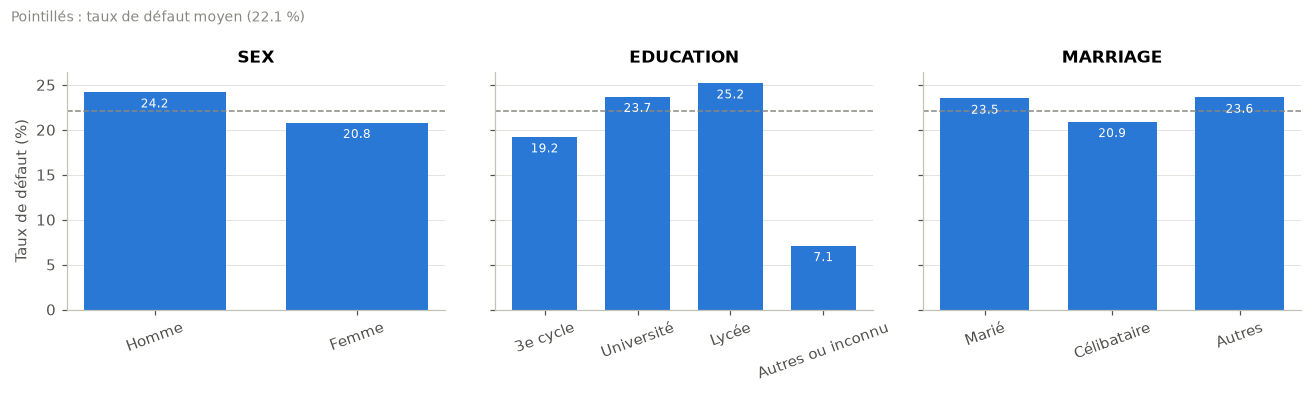

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6), sharey=True)
for ax, col in zip(axes, CATEGORICAL_FEATURES):
    barres_taux(ax, positive_rate_by(df, col, TARGET, categorical=True), col)
    ax.tick_params(axis="x", labelrotation=20)
axes[0].set_ylabel("Taux de défaut (%)")
note_moyenne(fig)
fig.tight_layout()
plt.show()

- **SEX :** 24,2 % de défaut chez les hommes contre 20,8 % chez les femmes.
- **EDUCATION :** le risque augmente quand le niveau d'études baisse (3e cycle 19,2 %, université
  23,7 %, lycée 25,2 %) ; « Autres ou inconnu » est nettement plus bas (7,1 %).
- **MARRIAGE :** écart modéré entre marié (23,5 %) et célibataire (20,9 %).

Ces trois variables sont **sensibles** (sexe, situation familiale, niveau d'études) : leur poids dans
les modèles sera mesuré et discuté dans l'analyse d'équité.

### 2.2 Statuts de remboursement : PAY_0 à PAY_6

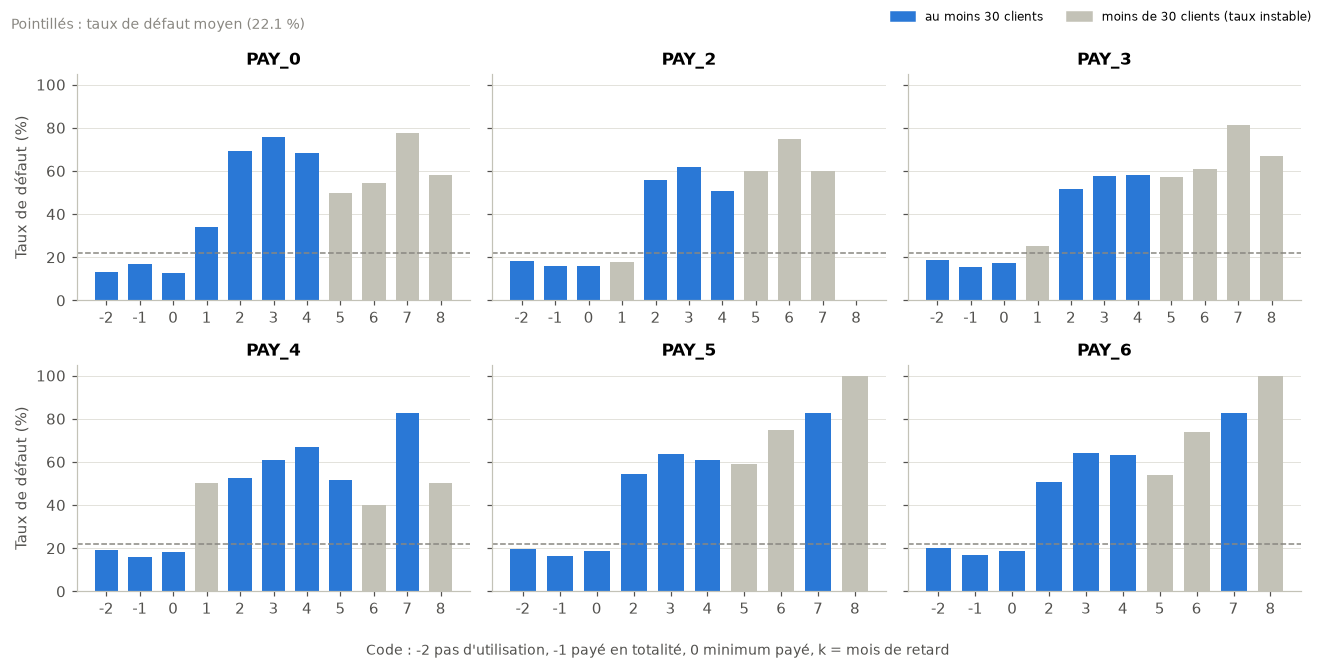

In [19]:
fig, axes = plt.subplots(2, 3, figsize=(12, 6), sharey=True)
for ax, col in zip(axes.flat, PAY_STATUS_FEATURES):
    table = positive_rate_by(df, col, TARGET, categorical=False)
    codes = [label.split(" : ")[0] for label in table.index]
    barres_taux(ax, table, col, etiquettes=codes, valeurs=False)
for ax in axes[:, 0]:
    ax.set_ylabel("Taux de défaut (%)")
fig.supxlabel("Code : -2 pas d'utilisation, -1 payé en totalité, 0 minimum payé, k = mois de retard",
              fontsize=9, color="#52514e")
note_moyenne(fig)
fig.legend(handles=[Patch(color=RATE_COLOR, label=f"au moins {PETIT_EFFECTIF} clients"),
                    Patch(color=GRIS, label=f"moins de {PETIT_EFFECTIF} clients (taux instable)")],
           loc="upper right", ncol=2, frameon=False, fontsize=8)
fig.tight_layout()
plt.show()

In [20]:
retards = pd.DataFrame({
    col: df.groupby(df[col] >= 1)[TARGET].mean().mul(100).round(1).rename({False: "sans retard", True: "retard ≥ 1 mois"})
    for col in PAY_STATUS_FEATURES
}).T
retards["clients en retard"] = [(df[col] >= 1).sum() for col in PAY_STATUS_FEATURES]
retards

,sans retard,retard ≥ 1 mois,clients en retard
PAY_0,13.8,50.3,6818
PAY_2,16.3,55.8,4438
PAY_3,17.2,52.3,4213
PAY_4,18.0,53.5,3510
PAY_5,18.4,55.6,2968
PAY_6,18.7,52.3,3079


- Pour chaque mois, le risque est **plat de -2 à 0**, puis **saute** dès qu'il y a du retard : environ
  14 à 19 % sans retard contre 50 à 56 % avec au moins un mois de retard. Relation non linéaire (M05).
- Les barres grises reposent sur moins de 30 clients (par exemple 100 % de défaut pour le code 8 en
  PAY_5 et PAY_6, avec 1 et 2 clients) : leurs hauteurs ne sont pas interprétables.
- L'anomalie de la section 1.4 est visible : le code 1 n'existe presque qu'en septembre (PAY_0).

### 2.3 Plafond de crédit et âge

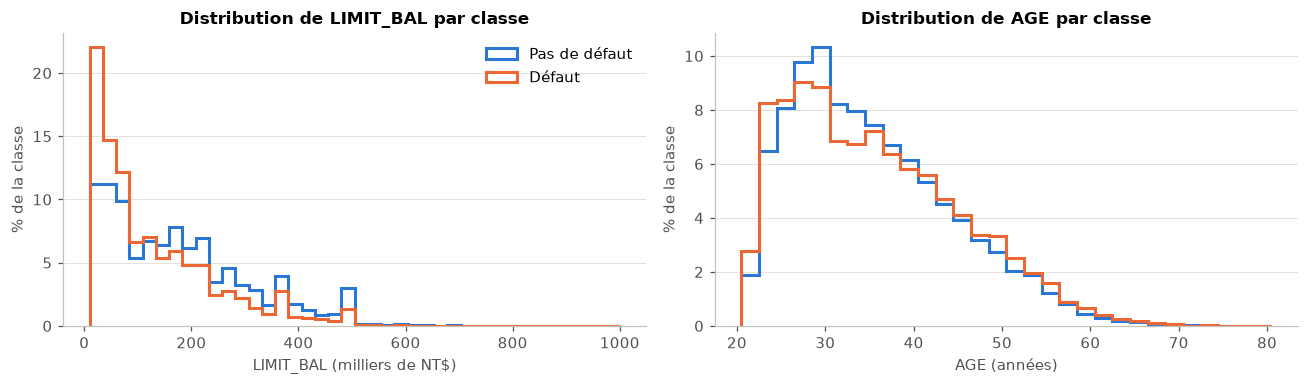

,LIMIT_BAL,AGE
DEFAULT,,
Pas de défaut,150000.0,34.0
Défaut,90000.0,34.0


In [21]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
# Âges entiers : tranches de 2 ans exactement, sinon les tranches contiennent tantôt 1, tantôt 2 âges.
for ax, (col, echelle, titre_x, bords) in zip(axes, [
    ("LIMIT_BAL", 1000, "LIMIT_BAL (milliers de NT$)", 40),
    ("AGE", 1, "AGE (années)", np.arange(20.5, 81, 2)),
]):
    valeurs = df[col] / echelle
    bords = np.histogram_bin_edges(valeurs, bins=bords)
    for cls in (0, 1):
        v = valeurs[df[TARGET] == cls]
        # Poids : chaque classe totalise 100 %, pour comparer les formes malgré le déséquilibre.
        ax.hist(v, bins=bords, weights=np.full(len(v), 100 / len(v)), histtype="step",
                linewidth=2, color=CLASS_COLORS[cls], label=NOMS_CLASSES[cls])
    ax.set_title(f"Distribution de {col} par classe")
    ax.set_xlabel(titre_x)
    ax.set_ylabel("% de la classe")
    ax.grid(axis="x", visible=False)
axes[0].legend(frameon=False)
fig.tight_layout()
plt.show()
df.groupby(TARGET)[["LIMIT_BAL", "AGE"]].median().rename(index=NOMS_CLASSES)

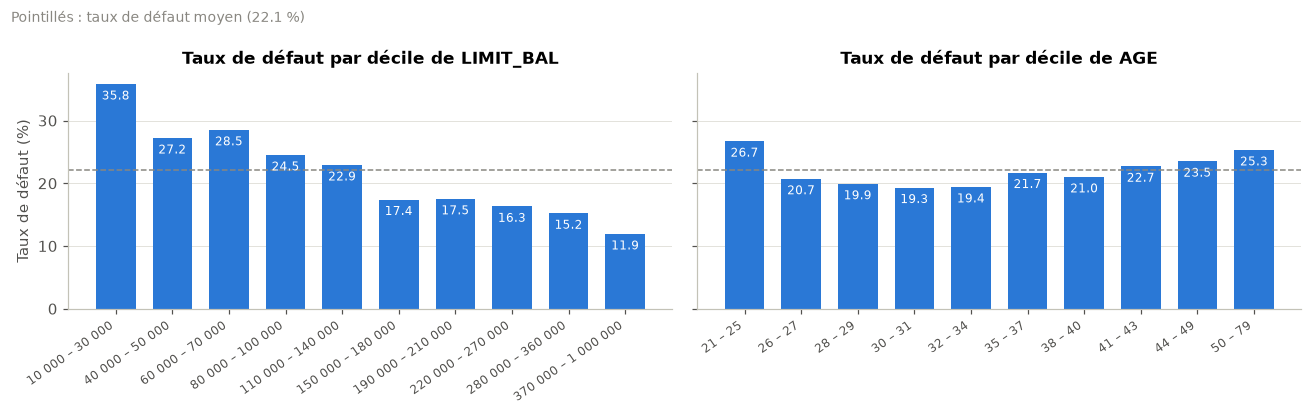

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for ax, col in zip(axes, ["LIMIT_BAL", "AGE"]):
    table = positive_rate_by(df, col, TARGET, categorical=False, n_bins=10)
    barres_taux(ax, table, f"Taux de défaut par décile de {col}")
    ax.tick_params(axis="x", labelrotation=35, labelsize=8)
    for label in ax.get_xticklabels():
        label.set_horizontalalignment("right")
axes[0].set_ylabel("Taux de défaut (%)")
note_moyenne(fig)
fig.tight_layout()
plt.show()

- **LIMIT_BAL :** les clients en défaut ont un plafond plus bas (médiane 90 000 contre 150 000) ; le
  taux de défaut baisse régulièrement de 35,8 % (premier décile) à 11,9 % (dernier décile). La banque
  accorde déjà des plafonds plus élevés aux clients qu'elle juge plus sûrs.
- **AGE :** même âge médian dans les deux classes (34 ans), mais une relation **en U** : 26,7 % chez
  les 21-25 ans, environ 19 % vers 30 ans, 25,3 % au-delà de 49 ans. Une corrélation linéaire ne
  verrait presque rien ; les arbres peuvent capter cette forme.

### 2.4 Corrélations entre variables numériques

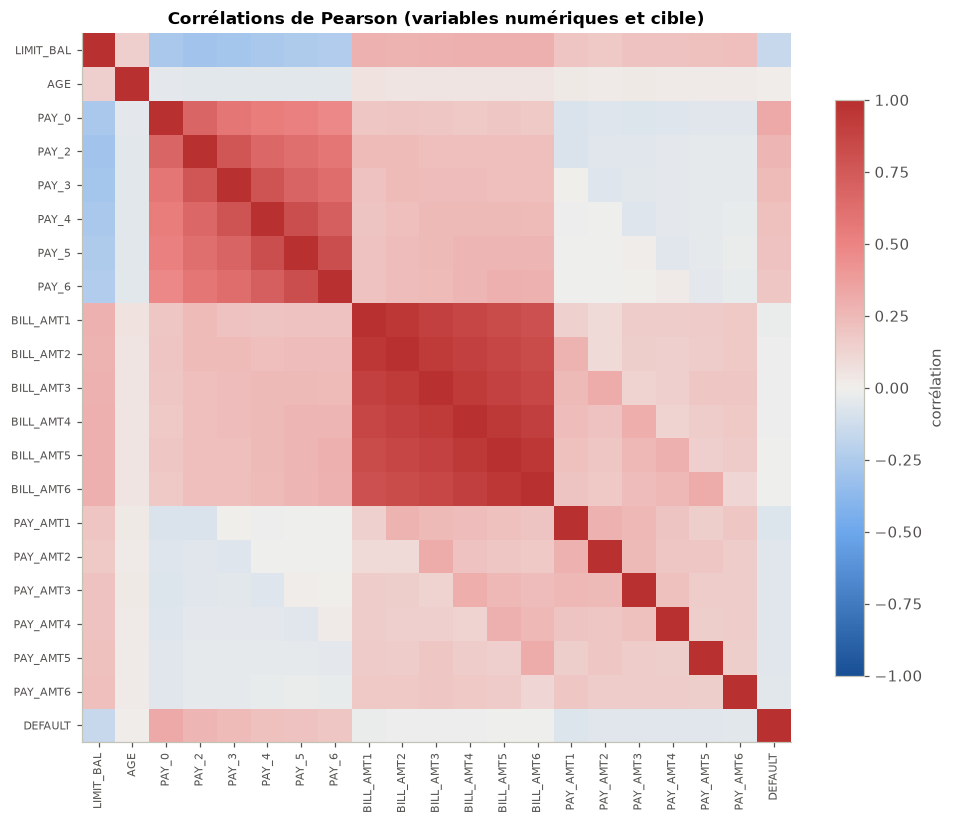

,corrélation avec DEFAULT
PAY_0,0.325
PAY_2,0.264
PAY_3,0.235
PAY_4,0.217
PAY_5,0.204
PAY_6,0.187
LIMIT_BAL,-0.154
PAY_AMT1,-0.073


In [23]:
numeriques = [c for c in df.columns if c not in CATEGORICAL_FEATURES]
corr = df[numeriques].corr()
palette = LinearSegmentedColormap.from_list("divergente", [(pos, couleur) for pos, couleur in DIVERGING])

fig, ax = plt.subplots(figsize=(9, 7.5))
image = ax.imshow(corr, cmap=palette, vmin=-1, vmax=1)
ax.set_xticks(range(len(numeriques)), numeriques, rotation=90, fontsize=7)
ax.set_yticks(range(len(numeriques)), numeriques, fontsize=7)
ax.grid(False)
ax.set_title("Corrélations de Pearson (variables numériques et cible)")
fig.colorbar(image, ax=ax, shrink=0.8, label="corrélation")
fig.tight_layout()
plt.show()
corr[TARGET].drop(TARGET).sort_values(key=abs, ascending=False).round(3).head(8).to_frame("corrélation avec DEFAULT")

- **Avec la cible :** PAY_0 est la variable la plus liée au défaut (0,325), puis les autres statuts
  de remboursement (0,26 à 0,19) et le plafond LIMIT_BAL (-0,154). Les montants de factures sont
  presque sans lien linéaire avec le défaut.
- **Entre variables :** les factures des six mois sont très corrélées entre elles (0,80 à 0,95), les
  statuts PAY_* un peu moins (0,47 à 0,82). Cette redondance gêne surtout la lecture des
  **coefficients** de la régression logistique (effets partagés entre variables corrélées) et répartit
  l'importance entre variables voisines dans les explications.
- Les variables catégorielles sont exclues : une corrélation sur des codes sans ordre n'a pas de sens.

### Synthèse de la section 2

| Constat | Conséquence pour la suite |
|---|---|
| Le retard de paiement récent (PAY_0) est le signal le plus fort | Variable attendue en tête des explications |
| Risque plat puis en saut selon PAY_*, en U selon l'âge | Relations non linéaires : avantage probable des arbres (M05) |
| Plafond bas = risque plus élevé | Effet attendu négatif de LIMIT_BAL |
| Factures très corrélées entre mois | Coefficients de la régression logistique à lire avec prudence |
| Écarts selon le sexe, l'éducation, la situation familiale | Analyse d'équité nécessaire |

## 3. Préparation des données

Même code que la page « 2. Préparation » de l'application (`credit_scoring.preprocessing`).
Décisions : P03 à P08 dans `docs/CHOIX.md`.

### 3.1 Variables explicatives

Les 23 variables d'origine sont utilisées (P07 : pas de nouvelles variables pour l'instant). Les
variables sensibles (SEX, AGE, MARRIAGE, EDUCATION) sont gardées par défaut (P08) ; l'analyse
d'équité comparera les modèles avec et sans elles.

In [24]:
from credit_scoring.config import RANDOM_STATE, SENSITIVE_FEATURES, TEST_SIZE
from credit_scoring.preprocessing import build_preprocessor, split_data, split_feature_types

variables = [c for c in df.columns if c != TARGET]
numeriques, categorielles = split_feature_types(df, variables, CATEGORICAL_FEATURES)
print(f"{len(variables)} variables : {len(numeriques)} numériques, {len(categorielles)} catégorielles {categorielles}")
print("Variables sensibles :", SENSITIVE_FEATURES)

23 variables : 20 numériques, 3 catégorielles ['SEX', 'EDUCATION', 'MARRIAGE']
Variables sensibles : ['SEX', 'AGE', 'MARRIAGE', 'EDUCATION']


### 3.2 Séparation entraînement / test

Séparation **stratifiée** 80 % / 20 %, graine 42 (P04). Elle est faite **avant tout apprentissage** :
le jeu de test est mis de côté et ne servira qu'à l'évaluation finale.

In [25]:
X_train, X_test, y_train, y_test = split_data(df, TARGET, variables, TEST_SIZE, RANDOM_STATE)
pd.DataFrame({
    "lignes": [len(X_train), len(X_test)],
    "défauts": [int(y_train.sum()), int(y_test.sum())],
    "taux de défaut (%)": [round(y_train.mean() * 100, 2), round(y_test.mean() * 100, 2)],
}, index=["entraînement", "test"])

,lignes,défauts,taux de défaut (%)
entraînement,24000,5309,22.12
test,6000,1327,22.12


La stratification conserve exactement le même taux de défaut dans les deux jeux. Sans elle, le
hasard pourrait donner un test un peu plus ou un peu moins risqué que l'entraînement, et fausser
la comparaison des modèles.

### 3.3 Prétraitement de la régression logistique : standardisation

Numériques : médiane si manquante, puis standardisation (moyenne 0, écart-type 1). Catégorielles :
modalité la plus fréquente si manquante, puis one-hot (P05, P06). Le prétraitement est ajusté
**sur l'entraînement seulement**, puis appliqué tel quel au test.

In [26]:
pre_lr = build_preprocessor(numeriques, categorielles, scale=True).fit(X_train)
train_lr, test_lr = pre_lr.transform(X_train), pre_lr.transform(X_test)
print(f"{train_lr.shape[1]} colonnes après prétraitement :")
print(list(train_lr.columns))

29 colonnes après prétraitement :
['LIMIT_BAL', 'AGE', 'PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6', 'BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6', 'PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6', 'SEX_1', 'SEX_2', 'EDUCATION_1', 'EDUCATION_2', 'EDUCATION_3', 'EDUCATION_4', 'MARRIAGE_1', 'MARRIAGE_2', 'MARRIAGE_3']


In [27]:
verification = pd.DataFrame({
    "moyenne (entraînement)": train_lr[numeriques].mean(),
    "écart-type (entraînement)": train_lr[numeriques].std(ddof=0),
    "moyenne (test)": test_lr[numeriques].mean(),
    "écart-type (test)": test_lr[numeriques].std(ddof=0),
}).round(3)
verification.loc[["LIMIT_BAL", "AGE", "PAY_0", "BILL_AMT1", "PAY_AMT1"]]

,moyenne (entraînement),écart-type (entraînement),moyenne (test),écart-type (test)
LIMIT_BAL,0.0,1.0,0.005,1.009
AGE,-0.0,1.0,0.029,1.012
PAY_0,0.0,1.0,-0.011,1.003
BILL_AMT1,0.0,1.0,0.008,1.009
PAY_AMT1,-0.0,1.0,0.012,1.123


**Preuve qu'il n'y a pas de fuite :** sur l'entraînement, moyenne 0 et écart-type 1 exactement ;
sur le test, des valeurs proches mais pas exactes. Le test est transformé avec la moyenne et
l'écart-type **de l'entraînement** : il n'a rien appris des données de test. Dans la modélisation,
ce prétraitement sera placé dans le Pipeline et réappris sur chaque pli de la validation croisée (P03).

### 3.4 Prétraitement des arbres : unités d'origine

Arbre de décision, Random Forest et XGBoost : imputation seulement pour les numériques, pas de
standardisation (P05). Les arbres ne dépendent pas de l'échelle ; garder les unités d'origine rend
leurs règles et les graphiques SHAP lisibles par un décideur.

In [28]:
pre_arbres = build_preprocessor(numeriques, categorielles, scale=False).fit(X_train)
train_arbres = pre_arbres.transform(X_train)
colonnes = ["LIMIT_BAL", "AGE", "PAY_0", "BILL_AMT1"]
pd.concat({
    "avant prétraitement": X_train[colonnes].head(3),
    "arbres (unités d'origine)": train_arbres[colonnes].head(3),
    "régression logistique (standardisé)": train_lr[colonnes].head(3).round(2),
}, axis=1)

avant prétraitement                     arbres (unités d'origine)        \
                LIMIT_BAL AGE PAY_0 BILL_AMT1                 LIMIT_BAL   AGE   
ID                                                                              
22789              160000  33     2    161771                  160000.0  33.0   
29007              150000  34     1         0                  150000.0  34.0   
16951               10000  50     1     10171                   10000.0  50.0   

                      régression logistique (standardisé)              \
      PAY_0 BILL_AMT1                           LIMIT_BAL   AGE PAY_0   
ID                                                                      
22789   2.0  161771.0                               -0.06 -0.26  1.79   
29007   1.0       0.0                               -0.13 -0.16  0.90   
16951   1.0   10171.0                               -1.22  1.58  0.90   

                 
      BILL_AMT1  
ID               
22789      1.51  
29007     -0.70  
16951     -0.56

In [29]:
print("Numériques identiques avant et après le prétraitement des arbres :",
      train_arbres[numeriques].equals(X_train[numeriques].astype(float)))
train_arbres.filter(like="EDUCATION_").head(3)

Numériques identiques avant et après le prétraitement des arbres : True


,EDUCATION_1,EDUCATION_2,EDUCATION_3,EDUCATION_4
ID,,,,
22789,0.0,1.0,0.0,0.0
29007,1.0,0.0,0.0,0.0
16951,0.0,1.0,0.0,0.0


### Synthèse de la section 3

| Étape | Résultat |
|---|---|
| Variables | 23 : 20 numériques (dont PAY_* ordinales), 3 catégorielles |
| Séparation | 24 000 / 6 000, taux de défaut identique (22,12 %) |
| Régression logistique | 29 colonnes, numériques standardisées sur l'entraînement |
| Arbres | 29 colonnes, numériques dans leur unité d'origine |
| Fuite de données | aucune : statistiques apprises sur l'entraînement seulement |

## 4. Modélisation

Quatre modèles : régression logistique et arbre de décision (basiques), Random Forest et XGBoost
(ensemblistes). Chaque modèle est un Pipeline « prétraitement → modèle » (section 3) placé dans un
**GridSearchCV** : validation croisée à 5 plis stratifiés **sur les 24 000 clients d'entraînement
seulement**, choix sur l'AUC. Décisions : M01 à M09 dans `docs/CHOIX.md`.

**Source des résultats :** le GridSearch complet prend une dizaine de minutes ; il est lancé une
fois par `python scripts/train.py`, qui écrit `models/resultats.json` et un tableau par modèle.
Cette section lit ces fichiers (sur un clone neuf, lancer d'abord le script).

In [30]:
from credit_scoring.comparison import REFERENCE_MODEL, comparison_table, thresholds_table
from credit_scoring.config import MODELS_DIR
from credit_scoring.models import MODEL_LABELS, default_grid, n_combinations
from credit_scoring.training import load_results

resultats = load_results(MODELS_DIR / "resultats.json")
resumes = resultats["modeles"]
grilles = {nom: pd.read_parquet(MODELS_DIR / f"grille_{nom}.parquet") for nom in resumes}
print("Versions :", resultats["meta"]["versions"])

Versions : {'python': '3.11.0', 'scikit-learn': '1.9.1', 'xgboost': '3.2.0'}


### 4.1 Grilles d'hyperparamètres

In [31]:
pd.DataFrame([
    {"modèle": MODEL_LABELS[nom],
     "grille": "; ".join(f"{k} ∈ {['sans limite' if v is None else v for v in vals]}" for k, vals in default_grid(nom).items()),
     "combinaisons": n_combinations(default_grid(nom)),
     "entraînements (× 5 plis)": n_combinations(default_grid(nom)) * 5}
    for nom in resumes
]).style.hide(axis="index")

modèle,grille,combinaisons,entraînements (× 5 plis)
Régression logistique,"C ∈ [0.01, 0.1, 1, 10]",4,20
Arbre de décision,"max_depth ∈ [3, 5, 8, 12, 16, 20]; min_samples_leaf ∈ [1, 20, 50, 100, 200, 400, 800, 1600]",48,240
Random Forest,"max_depth ∈ [8, 12, 'sans limite']; min_samples_leaf ∈ [1, 10]; max_features ∈ ['sqrt', 0.5]",12,60
XGBoost,"n_estimators ∈ [300, 500, 800]; learning_rate ∈ [0.01, 0.02, 0.03]; max_depth ∈ [3, 4, 5]; subsample ∈ [0.4, 0.6, 0.8]",81,405


Aucune pondération des classes dans les grilles finales (M03) : testée dans un premier GridSearch,
elle n'améliorait pas l'AUC des meilleures combinaisons et faussait les probabilités.

| Modèle | Meilleure AUC avec pondération | Meilleure AUC sans | Écart |
|---|---|---|---|
| Régression logistique | 0,7276 | 0,7272 | +0,0004 |
| Arbre de décision | 0,7598 | 0,7665 | −0,0066 |
| Random Forest | 0,7849 | 0,7845 | +0,0004 |
| XGBoost | 0,7829 | 0,7828 | +0,0001 |

*(Chiffres du premier GridSearch, conservés dans `docs/CHOIX.md` ; variation entre plis : 0,005 à 0,011.)*

### 4.2 Tableau comparatif (validation croisée)

In [32]:
tableau = comparison_table(resumes).drop(columns="_cle")
tableau.round({"AUC": 4, "écart-type AUC": 4, "Gini": 4, "PR-AUC": 4, "AUC entraînement": 4,
               "écart entr. − valid.": 4, "proba. moyenne (%)": 2, "taux réel (%)": 2,
               "durée (s)": 1, "taille (Mo)": 3})

,modèle,AUC,écart-type AUC,Gini,PR-AUC,AUC entraînement,écart entr. − valid.,proba. moyenne (%),taux réel (%),combinaisons,durée (s),taille (Mo)
0,XGBoost,0.7860,0.0054,0.5720,0.5655,0.8311,0.0451,22.05,22.12,81,241.8,0.398
1,Random Forest,0.7845,0.0048,0.5691,0.5595,0.9318,0.1473,22.31,22.12,12,260.0,12.294
2,Arbre de décision,0.7707,0.0041,0.5414,0.5278,0.7858,0.0151,22.11,22.12,48,16.6,0.006
3,Régression logistique,0.7272,0.0115,0.4544,0.5068,0.7300,0.0028,22.11,22.12,4,6.1,0.003


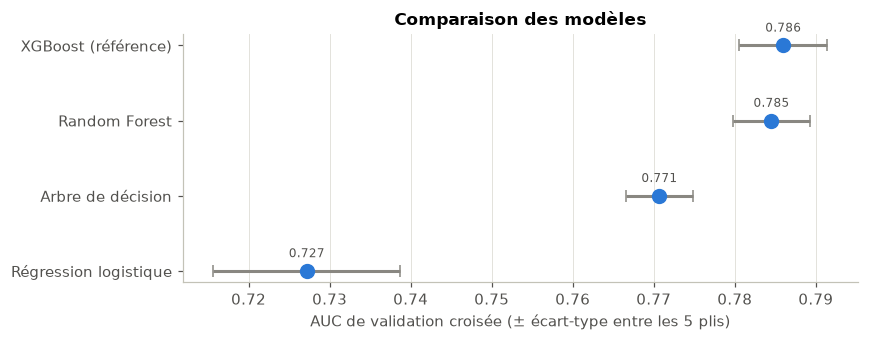

In [33]:
ordre = tableau.sort_values("AUC")
etiquettes = [f"{m} (référence)" if m == MODEL_LABELS[REFERENCE_MODEL] else m for m in ordre["modèle"]]

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.errorbar(ordre["AUC"], etiquettes, xerr=ordre["écart-type AUC"], fmt="o", color=RATE_COLOR,
            ecolor=MUTED, elinewidth=2, capsize=4, markersize=9)
for x, y in zip(ordre["AUC"], etiquettes):
    ax.annotate(f"{x:.3f}", (x, y), textcoords="offset points", xytext=(0, 9), ha="center", fontsize=8, color="#52514e")
ax.set_xlabel("AUC de validation croisée (± écart-type entre les 5 plis)")
ax.set_title("Comparaison des modèles")
ax.grid(axis="y", visible=False)
fig.tight_layout()
plt.show()

- **Random Forest et XGBoost sont à égalité** (0,785 et 0,786) : l'écart est dix fois plus petit que la
  variation d'un pli à l'autre. Les barres d'erreur se chevauchent.
- **La régression logistique est nettement derrière** (0,727) : sa forme linéaire ne peut pas
  représenter le risque plat de PAY_0 = -2 à 0 puis le saut au premier mois de retard (M05). Ce
  n'est pas une question de régularisation : son AUC varie de 0,001 entre `C` = 0,01 et 10.
- **Probabilités cohérentes :** sans pondération, la probabilité moyenne prédite (22,05 à 22,31 %)
  correspond au taux réel de défaut (22,12 %). La calibration tranche par tranche sera vérifiée à
  l'étape d'évaluation (E03).

### 4.3 Surapprentissage : AUC sur les clients vus et non vus

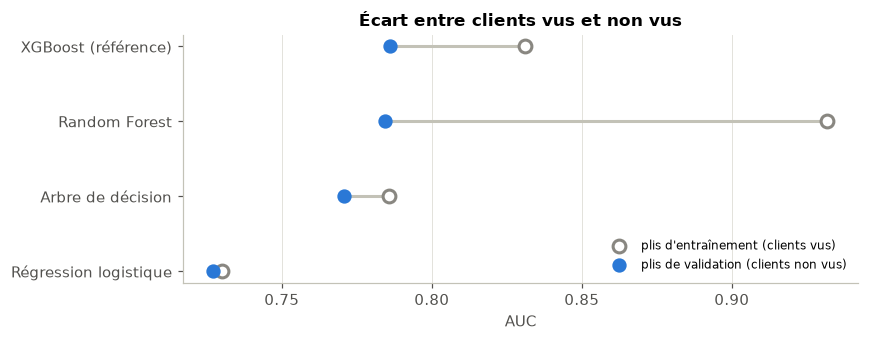

In [34]:
fig, ax = plt.subplots(figsize=(8, 3.2))
for i, (_, ligne) in enumerate(ordre.iterrows()):
    ax.plot([ligne["AUC"], ligne["AUC entraînement"]], [i, i], color=GRIS, linewidth=2, zorder=1)
ax.scatter(ordre["AUC entraînement"], range(len(ordre)), s=70, facecolor="white", edgecolor=MUTED,
           linewidth=2, zorder=2, label="plis d'entraînement (clients vus)")
ax.scatter(ordre["AUC"], range(len(ordre)), s=70, color=RATE_COLOR, zorder=3,
           label="plis de validation (clients non vus)")
ax.set_yticks(range(len(ordre)), etiquettes)
ax.set_xlabel("AUC")
ax.set_title("Écart entre clients vus et non vus")
ax.legend(frameon=False, fontsize=8, loc="lower right")
ax.grid(axis="y", visible=False)
fig.tight_layout()
plt.show()

- **Random Forest mémorise fortement** (0,93 sur les clients vus, 0,78 sur les autres) : ses arbres sont
  profonds ; la moyenne de 300 arbres compense, d'où un bon score en validation, mais un fichier lourd.
- **XGBoost** (écart 0,045) et **l'arbre de décision** (0,015) généralisent beaucoup mieux ;
  la régression logistique (0,003) est trop simple pour surapprendre.

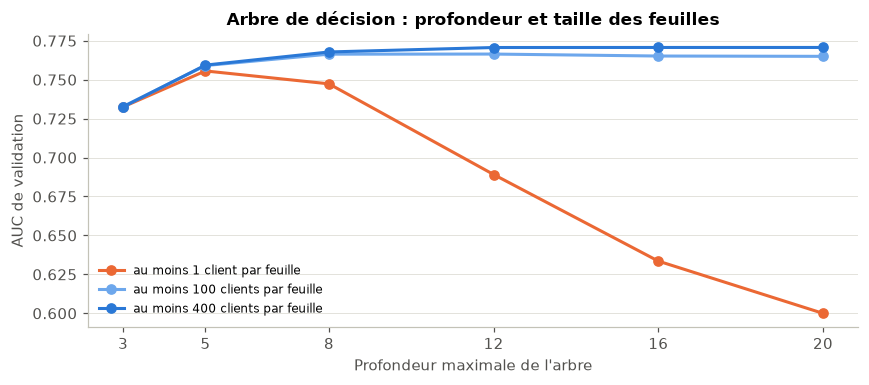

max_depth,3,5,8,12,16,20
meilleure AUC,0.734,0.7594,0.7678,0.7707,0.7707,0.7707


In [35]:
arbre = grilles["arbre"]
fig, ax = plt.subplots(figsize=(8, 3.6))
for feuille, couleur in [(1, "#eb6834"), (100, "#6da7ec"), (400, RATE_COLOR)]:
    courbe = arbre[arbre["min_samples_leaf"] == feuille].sort_values("max_depth")
    ax.plot(courbe["max_depth"], courbe["mean_test_roc_auc"], marker="o", linewidth=2, color=couleur,
            label=f"au moins {feuille} client{'s' if feuille > 1 else ''} par feuille")
ax.set_xticks(sorted(arbre["max_depth"].unique()))
ax.set_xlabel("Profondeur maximale de l'arbre")
ax.set_ylabel("AUC de validation")
ax.set_title("Arbre de décision : profondeur et taille des feuilles")
ax.legend(frameon=False, fontsize=8)
ax.grid(axis="x", visible=False)
fig.tight_layout()
plt.show()
arbre.groupby("max_depth")["mean_test_roc_auc"].max().round(4).rename("meilleure AUC").to_frame().T

- **Surapprentissage visible :** avec des feuilles d'un seul client, l'AUC **chute** quand l'arbre devient
  profond (jusqu'à 0,60 à profondeur 20) : l'arbre apprend les clients par cœur. Imposer au moins
  400 clients par feuille empêche les règles fondées sur une poignée de cas.
- **Coût d'un arbre lisible (M08) :** profondeur 3 (au plus 8 règles) : AUC 0,734, contre 0,771
  pour le meilleur arbre et 0,786 pour XGBoost, soit **−0,052 d'AUC** pour un modèle qu'un décideur
  peut lire en entier.

### 4.4 Surface de réglage de XGBoost

In [36]:
xgb = grilles["xgboost"]
xgb.head(10)[["n_estimators", "learning_rate", "max_depth", "subsample", "mean_test_roc_auc", "mean_train_roc_auc"]].round(4)

,n_estimators,learning_rate,max_depth,subsample,mean_test_roc_auc,mean_train_roc_auc
0,500.0,0.01,5.0,0.4,0.7860,0.8311
1,300.0,0.03,5.0,0.4,0.7858,0.8564
2,800.0,0.01,5.0,0.4,0.7858,0.8524
3,500.0,0.02,4.0,0.4,0.7857,0.8339
4,800.0,0.01,4.0,0.4,0.7855,0.8263
5,800.0,0.01,5.0,0.6,0.7854,0.8544
6,500.0,0.01,5.0,0.6,0.7853,0.8323
7,300.0,0.02,5.0,0.4,0.7853,0.8379
8,300.0,0.03,4.0,0.4,0.7852,0.8295
9,500.0,0.02,5.0,0.4,0.7850,0.8629


Les 10 meilleures combinaisons tiennent en **0,0009** d'AUC, pour une variation entre plis de 0,0054 :
la surface est presque plate. Trois réglages restent en bord de grille après deux prolongements
(taux 0,01, profondeur 5, sous-échantillon 0,4) ; les pousser plus loin ferait gagner moins que le
bruit (M06, limite citée telle quelle).

### 4.5 Seuils de décision

In [37]:
thresholds_table(resumes).round(3)

,modèle,critère,seuil,précision (%),rappel (%),F1,clients signalés (%),KS
0,Régression logistique,F1 maximal (recommandé),0.291,55.503,48.258,0.516,19.233,NaN
1,Régression logistique,KS,0.260,48.253,54.116,0.510,24.808,0.376
2,Arbre de décision,F1 maximal (recommandé),0.262,47.739,59.842,0.531,27.729,NaN
3,Arbre de décision,KS,0.251,46.094,61.801,0.528,29.658,0.413
4,Random Forest,F1 maximal (recommandé),0.287,52.558,57.092,0.547,24.029,NaN
5,Random Forest,KS,0.258,49.822,60.520,0.547,26.871,0.432
6,XGBoost,F1 maximal (recommandé),0.269,52.618,57.167,0.548,24.033,NaN
7,XGBoost,KS,0.207,45.512,66.095,0.539,32.125,0.436


Seuils choisis sur les **prédictions hors pli** de l'entraînement (chaque client est prédit par un modèle
qui ne l'a pas vu), jamais sur le test (E01). **F1 maximal** (recommandé) contre **KS** : le seuil du KS est
plus bas ; pour XGBoost, il signale 32 % des clients au lieu de 24 %, détecte 66 % des défauts au lieu
de 57 %, mais avec une précision de 45 % au lieu de 53 %.

### 4.6 Modèle de référence : XGBoost (M07)

Choisi **sur la validation croisée, avant toute utilisation du jeu de test** :

| Critère | XGBoost | Random Forest |
|---|---|---|
| AUC de validation | 0,786 | 0,785 (égalité) |
| Écart entraînement − validation | 0,045 | 0,147 |
| Taille du fichier | 0,40 Mo | 12,3 Mo |
| Probabilité moyenne (taux réel 22,12 %) | 22,05 % | 22,31 % |

### Synthèse de la section 4

| Constat | Conséquence |
|---|---|
| XGBoost et Random Forest à égalité (0,786 / 0,785) | XGBoost retenu : plus léger, moins de surapprentissage |
| Régression logistique à 0,727 | Prix de la linéarité (M05) ; à comparer à son interprétabilité |
| Arbre lisible (profondeur 3) à 0,734 | −0,052 d'AUC pour un modèle lisible en entier |
| Pondération sans effet sur l'AUC | Retirée : probabilités cohérentes avec le taux réel |
| Seuil F1 : 24 % des clients signalés, 57 % des défauts détectés | À confirmer sur le test (étape d'évaluation) |

## 5. Évaluation sur le jeu de test

Les 6 000 clients mis de côté à la section 3 servent ici **pour la première fois**. Le modèle de
référence (XGBoost) et le seuil de chaque modèle (F1 maximal sur les prédictions hors pli) sont
**déjà fixés** : le test sert à mesurer, jamais à choisir. Décisions : E01 à E06 dans `docs/CHOIX.md`.

In [38]:
from sklearn.metrics import precision_recall_curve, roc_curve

from credit_scoring.comparison import auc_differences, holdout_table
from credit_scoring.evaluation import (bootstrap_auc, calibration_table, confusion_counts,
                                       decision_sentence, metrics_at_threshold)
from credit_scoring.plots import MODEL_COLORS
from credit_scoring.reference import load_reference, reference_split

resultats, modeles = load_reference()
_, X_test_ref, _, y_test_ref = reference_split(resultats["meta"])
probas = {nom: m.predict_proba(X_test_ref)[:, 1] for nom, m in modeles.items()}
seuils = {nom: resultats["modeles"][nom]["seuils"]["f1_max"]["seuil"] for nom in modeles}
print(f"Test : {len(y_test_ref)} clients, {int(y_test_ref.sum())} défauts ({y_test_ref.mean():.2%})")

Test : 6000 clients, 1327 défauts (22.12%)


### 5.1 Métriques sur le test

Chaque modèle est évalué à son seuil F1 fixé sur l'entraînement. L'intervalle de confiance de l'AUC
vient d'un **bootstrap apparié** : 1 000 tirages avec remise des 6 000 clients, les mêmes pour tous les
modèles (E05).

In [39]:
bootstrap = bootstrap_auc(y_test_ref, probas, n_resamples=1000)
metriques_test = holdout_table(y_test_ref, probas, resultats["modeles"], bootstrap)
metriques_test.drop(columns="_cle").round({
    "AUC validation croisée": 4, "AUC test": 4, "IC 95 % bas": 4, "IC 95 % haut": 4, "Gini": 4, "KS": 4,
    "PR-AUC": 4, "Brier": 4, "proba. moyenne (%)": 2, "seuil": 3, "précision (%)": 1, "rappel (%)": 1,
    "F1": 4, "clients signalés (%)": 1})

,modèle,AUC validation croisée,AUC test,IC 95 % bas,IC 95 % haut,Gini,KS,PR-AUC,Brier,proba. moyenne (%),seuil,précision (%),rappel (%),F1,clients signalés (%)
0,XGBoost,0.7860,0.7791,0.7650,0.7947,0.5581,0.4272,0.5578,0.1352,22.13,0.269,52.2,56.0,0.5404,23.7
1,Random Forest,0.7845,0.7743,0.7596,0.7896,0.5486,0.4284,0.5523,0.1355,22.34,0.287,52.1,56.7,0.5433,24.1
2,Arbre de décision,0.7707,0.7653,0.7504,0.7813,0.5306,0.3985,0.5280,0.1376,22.13,0.262,47.1,57.8,0.5191,27.1
3,Régression logistique,0.7272,0.7101,0.6931,0.7285,0.4201,0.3639,0.4951,0.1466,22.15,0.291,53.6,46.8,0.4998,19.3


In [40]:
auc_differences(bootstrap, resultats["modeles"]).round(4)

,comparaison,écart d'AUC,IC 95 % bas,IC 95 % haut,conclusion
0,XGBoost − Régression logistique,0.0691,0.0556,0.0823,référence meilleure
1,XGBoost − Arbre de décision,0.0136,0.0069,0.0204,référence meilleure
2,XGBoost − Random Forest,0.0047,-0.0003,0.0094,égalité (l'intervalle contient 0)


- **Le classement de la validation croisée se confirme** sur des clients jamais vus : XGBoost (0,779),
  Random Forest (0,774), arbre (0,765), régression logistique (0,710). Les AUC baissent de 0,005 à
  0,017 par rapport à la validation croisée (qui a servi à régler, donc légèrement optimiste), et
  chaque valeur de validation croisée reste dans l'intervalle de confiance du test.
- **XGBoost et Random Forest restent à égalité** : l'intervalle de leur écart contient 0. XGBoost est
  significativement meilleur que l'arbre (+0,014) et que la régression logistique (+0,069).
- **Le seuil tient** : pour XGBoost, F1 de 0,548 en validation et 0,540 sur le test.

### 5.2 Courbes ROC et précision-rappel

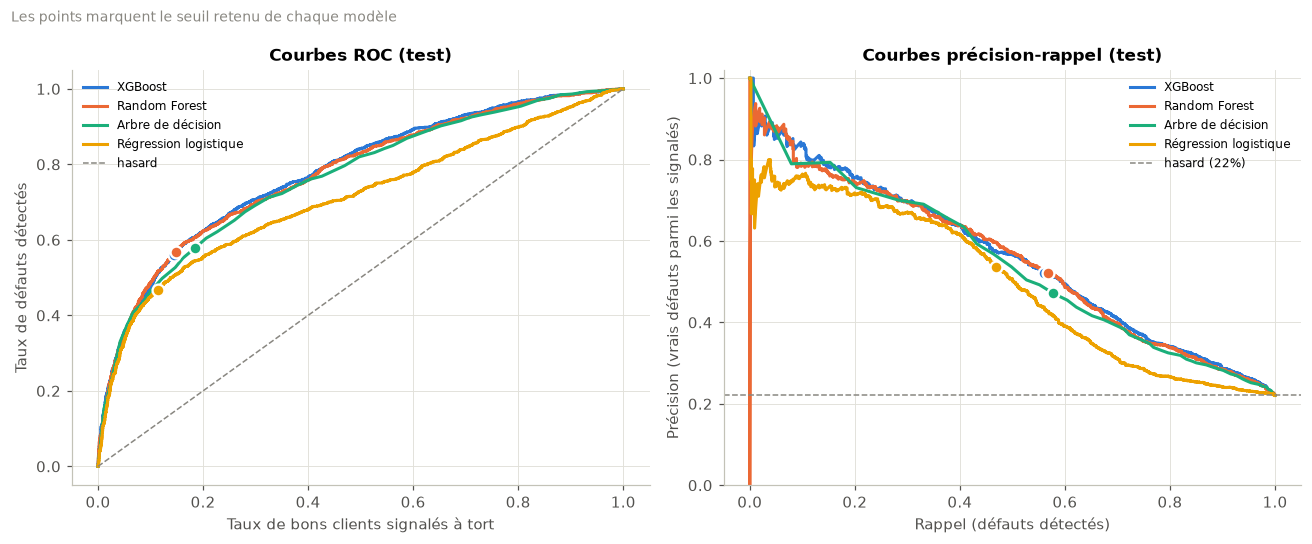

In [41]:
fig, (ax_roc, ax_pr) = plt.subplots(1, 2, figsize=(12, 5))
ordre_modeles = list(metriques_test["_cle"])
for nom in ordre_modeles:
    couleur, libelle = MODEL_COLORS[nom], resultats["modeles"][nom]["libelle"]
    fpr, tpr, _ = roc_curve(y_test_ref, probas[nom])
    ax_roc.plot(fpr, tpr, color=couleur, linewidth=2, label=libelle)
    precision, rappel, _ = precision_recall_curve(y_test_ref, probas[nom])
    ax_pr.plot(rappel, precision, color=couleur, linewidth=2, label=libelle)
    c = confusion_counts(y_test_ref, probas[nom], seuils[nom])
    ax_roc.scatter(c["fp"] / (c["fp"] + c["vn"]), c["vp"] / (c["vp"] + c["fn"]), s=60, color=couleur,
                   edgecolor="white", linewidth=1.5, zorder=3)
    m = metrics_at_threshold(y_test_ref, probas[nom], seuils[nom])
    ax_pr.scatter(m["rappel"], m["precision"], s=60, color=couleur, edgecolor="white", linewidth=1.5, zorder=3)
ax_roc.plot([0, 1], [0, 1], color=MUTED, linestyle="--", linewidth=1, label="hasard")
ax_pr.axhline(y_test_ref.mean(), color=MUTED, linestyle="--", linewidth=1, label=f"hasard ({y_test_ref.mean():.0%})")
ax_roc.set(title="Courbes ROC (test)", xlabel="Taux de bons clients signalés à tort", ylabel="Taux de défauts détectés")
ax_pr.set(title="Courbes précision-rappel (test)", xlabel="Rappel (défauts détectés)",
          ylabel="Précision (vrais défauts parmi les signalés)", ylim=(0, 1.02))
for ax in (ax_roc, ax_pr):
    ax.legend(frameon=False, fontsize=8)
fig.suptitle("Les points marquent le seuil retenu de chaque modèle", x=0.01, ha="left", fontsize=9,
             color=MUTED, fontweight="normal")
fig.tight_layout()
plt.show()

XGBoost et Random Forest se confondent presque (leurs points de seuil se superposent : le point bleu
de XGBoost est caché sous celui de Random Forest) ; la régression logistique est nettement en dessous
sur toute la courbe. La ligne du hasard de la courbe précision-rappel est le taux de défaut (22 %) :
au seuil retenu, XGBoost double environ cette précision.

### 5.3 Matrice de confusion et effet du seuil (XGBoost)

In [42]:
comptes = confusion_counts(y_test_ref, probas["xgboost"], seuils["xgboost"])
pd.DataFrame([[comptes["vp"], comptes["fn"]], [comptes["fp"], comptes["vn"]]],
             index=["défaut réel", "pas de défaut réel"],
             columns=["prédit « défaut »", "prédit « pas de défaut »"])

,prédit « défaut »,prédit « pas de défaut »
défaut réel,743,584
pas de défaut réel,680,3993


In [43]:
print(decision_sentence(comptes))

Sur 6 000 clients, le modèle en signale 1 423 comme risqués : 743 d'entre eux font réellement défaut (52 %). Il manque 584 défauts sur 1 327.


In [44]:
seuil_ks = resultats["modeles"]["xgboost"]["seuils"]["ks"]["seuil"]
lignes = []
for libelle, s in [("KS (choisi sur l'entraînement)", seuil_ks), ("0,20", 0.20),
                   ("recommandé (F1 max.)", seuils["xgboost"]),
                   ("0,40", 0.40), ("0,50", 0.50)]:
    m = metrics_at_threshold(y_test_ref, probas["xgboost"], s)
    c = confusion_counts(y_test_ref, probas["xgboost"], s)
    lignes.append({"seuil": f"{libelle} = {s:.3f}", "clients signalés": c["vp"] + c["fp"],
                   "vrais défauts parmi eux": c["vp"], "défauts manqués": c["fn"],
                   "précision (%)": round(m["precision"] * 100, 1), "rappel (%)": round(m["rappel"] * 100, 1),
                   "F1": round(m["f1"], 3)})
pd.DataFrame(lignes).set_index("seuil")

,clients signalés,vrais défauts parmi eux,défauts manqués,précision (%),rappel (%),F1
seuil,,,,,,
KS (choisi sur l'entraînement) = 0.207,1906,856,471,44.9,64.5,0.530
"0,20 = 0.200",1988,873,454,43.9,65.8,0.527
recommandé (F1 max.) = 0.269,1423,743,584,52.2,56.0,0.540
"0,40 = 0.400",926,565,762,61.0,42.6,0.502
"0,50 = 0.500",712,476,851,66.9,35.9,0.467


**Le compromis du seuil :** plus il est bas, plus on détecte de défauts (rappel), mais plus on signale
de bons clients à tort (précision qui baisse). Le seuil recommandé maximise le F1, c'est-à-dire
l'équilibre entre les deux ; un seuil plus bas convient si un défaut manqué coûte bien plus cher
qu'un bon client refusé. Ce choix appartient au décideur ; l'application le rend visible avec un curseur.

### 5.4 Séparation des classes : statistique de Kolmogorov-Smirnov

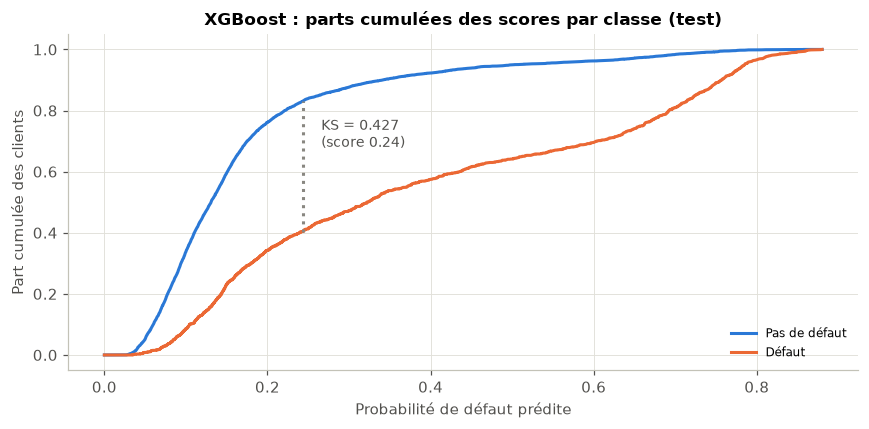

In [45]:
p = probas["xgboost"]
y = np.asarray(y_test_ref)
grille_scores = np.concatenate([[0.0], np.unique(p)])
cumul = {cls: np.searchsorted(np.sort(p[y == cls]), grille_scores, side="right") / (y == cls).sum() for cls in (0, 1)}
ecart = cumul[0] - cumul[1]
i_max = int(np.argmax(ecart))

fig, ax = plt.subplots(figsize=(8, 4))
for cls in (0, 1):
    ax.plot(grille_scores, cumul[cls], color=CLASS_COLORS[cls], linewidth=2, label=NOMS_CLASSES[cls])
ax.vlines(grille_scores[i_max], cumul[1][i_max], cumul[0][i_max], color=MUTED, linestyle=":", linewidth=2)
ax.annotate(f"KS = {ecart[i_max]:.3f}\n(score {grille_scores[i_max]:.2f})", (grille_scores[i_max], cumul[0][i_max]),
            xytext=(12, -30), textcoords="offset points", fontsize=9, color="#52514e")
ax.set(title="XGBoost : parts cumulées des scores par classe (test)", xlabel="Probabilité de défaut prédite",
       ylabel="Part cumulée des clients")
ax.legend(frameon=False, fontsize=8, loc="lower right")
fig.tight_layout()
plt.show()

Chaque courbe donne la part des clients dont le score est inférieur à une valeur. Les bons payeurs
(bleu) ont des scores bas : leur courbe monte vite. Les défauts (orange) ont des scores plus élevés.
Le **KS** est le plus grand écart vertical entre les deux courbes ; une valeur autour de 0,4 est
jugée correcte en scoring de crédit.

**Deux seuils « KS » à ne pas confondre :** sur ce graphique, l'écart maximal **sur le test** est atteint
au score 0,24 ; le seuil du KS du tableau ci-dessus (0,207) a été **choisi sur l'entraînement** (prédictions
hors pli), comme tous les seuils appliqués. Autour du maximum, la courbe de l'écart est presque plate
(de 0,419 à 0,427 entre les scores 0,19 et 0,25) : appliquer 0,207 ne coûte que 0,006 de KS sur le test.

### 5.5 Calibration du modèle de référence (E03)

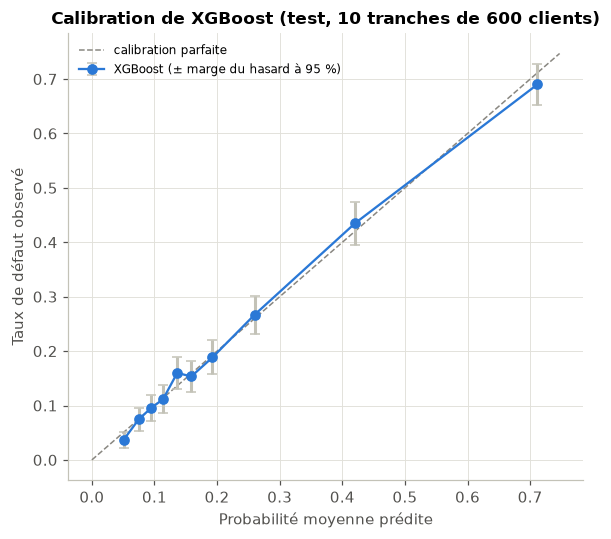

Score de Brier : 0.1352 (modèle naïf qui annonce 22.12% à tous : 0.1723, soit 21.5% d'erreur en moins)


,clients,proba_moyenne,taux_observe,écart (points),marge du hasard (points)
0,600,0.0506,0.0367,-1.3912,0.7673
1,600,0.0751,0.0750,-0.0067,1.0753
2,600,0.0943,0.0950,0.0729,1.1970
3,600,0.1137,0.1117,-0.2052,1.2858
4,600,0.1363,0.1600,2.3653,1.4967
5,600,0.1587,0.1533,-0.5319,1.4710
6,600,0.1925,0.1883,-0.4192,1.5962
7,600,0.2597,0.2667,0.6937,1.8053
8,600,0.4203,0.4350,1.4671,2.0239
9,600,0.7114,0.6900,-2.1405,1.8881


In [46]:
calibration = calibration_table(y_test_ref, probas["xgboost"], n_bins=10)
calibration["écart (points)"] = (calibration["taux_observe"] - calibration["proba_moyenne"]) * 100
calibration["marge du hasard (points)"] = np.sqrt(
    calibration["taux_observe"] * (1 - calibration["taux_observe"]) / calibration["clients"]) * 100

fig, ax = plt.subplots(figsize=(5.5, 5))
limite = float(max(calibration["proba_moyenne"].max(), calibration["taux_observe"].max())) * 1.05
ax.plot([0, limite], [0, limite], color=MUTED, linestyle="--", linewidth=1, label="calibration parfaite")
ax.errorbar(calibration["proba_moyenne"], calibration["taux_observe"],
            yerr=1.96 * calibration["marge du hasard (points)"] / 100, fmt="o-", color=RATE_COLOR,
            ecolor=GRIS, elinewidth=2, capsize=3, label="XGBoost (± marge du hasard à 95 %)")
ax.set(title="Calibration de XGBoost (test, 10 tranches de 600 clients)", xlabel="Probabilité moyenne prédite",
       ylabel="Taux de défaut observé")
ax.legend(frameon=False, fontsize=8)
fig.tight_layout()
plt.show()

brier = float(np.mean((probas["xgboost"] - y) ** 2))
naif = y.mean() * (1 - y.mean())
print(f"Score de Brier : {brier:.4f} (modèle naïf qui annonce {y.mean():.2%} à tous : {naif:.4f}, "
      f"soit {1 - brier / naif:.1%} d'erreur en moins)")
calibration.round(4)

Les points suivent la diagonale : écart moyen de 0,9 point, au plus 2,4 points, toujours à moins de
2 marges d'erreur du hasard. Une probabilité annoncée de 40 % correspond bien à environ 40 % de
défauts observés : **aucune recalibration n'est nécessaire**.

### Synthèse de la section 5

| Constat | Valeur (XGBoost, test) |
|---|---|
| AUC [IC 95 %] | 0,779 [0,765 ; 0,795], Gini 0,558, KS 0,427 |
| Écart avec Random Forest | +0,005 [−0,000 ; +0,009] : égalité |
| Au seuil recommandé | 1 423 clients signalés, 743 défauts (52 %), 584 défauts manqués sur 1 327 |
| Calibration | fiable : écarts compatibles avec le hasard, Brier −21,5 % par rapport au modèle naïf |